# Zomato Bengaluru Restaurant Data Analysis
### Data cleaning • Exploratory analysis • Visualisation • Evidence-based insights

**Author:** Abhiram Reddy

## Project overview
This project explores a historical snapshot of restaurant listings in Bengaluru from a Zomato dataset. It examines how listings are distributed across neighbourhoods, how ratings and approximate costs vary, and how recorded service options relate to ratings and prices.

The notebook combines a careful, reproducible cleaning workflow with a broader set of visual investigations. It is designed to distinguish descriptive patterns from conclusions the data cannot support.

## Questions explored
1. Which neighbourhoods have the most restaurant listings?
2. How are restaurant ratings distributed?
3. Which restaurant types and cuisine tags occur most frequently?
4. How do ratings differ between listings with and without online ordering?
5. How do ratings differ between listings with and without table booking?
6. What relationship, if any, is visible between approximate cost and rating?
7. How do rating and cost vary across price bands?
8. How does approximate cost differ by table-booking availability?
9. Which restaurant types have higher average ratings, with minimum sample-size safeguards?
10. How do average ratings vary across neighbourhoods with sufficient listings?
11. How are votes distributed across rating bands, and how common is online ordering across neighbourhoods?

## Important interpretation principles
- These are observational, descriptive analyses. They do **not** establish causation.
- A higher group average does not prove that a service option causes higher ratings.
- Results depend on the dataset's collection period, coverage and missing values.
- The dataset has no reliable time variable for trend analysis.
- Restaurant listings are not necessarily unique businesses or active establishments today.

## 1. Set up the project

Expected project layout:

```text
zomato-restaurant-analysis/
├── data/
│   └── raw/
│       └── zomato.csv          # supplied locally by the user; not committed
├── notebooks/
│   └── zomato_eda.ipynb
├── outputs/
│   └── visualizations/
├── docs/
├── README.md
└── requirements.txt
```

Install the dependencies from the project root:

```bash
pip install -r requirements.txt
```

Place your permitted local copy of the dataset at `data/raw/zomato.csv`. The notebook searches the current working directory and its parent directories for this project structure.

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid", context="notebook")

PROJECT_ROOT = Path.cwd()
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "notebooks").exists() and (candidate / "requirements.txt").exists():
        PROJECT_ROOT = candidate
        break

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "zomato.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "visualizations"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at: {DATA_PATH}\n"
        "Place your local CSV at data/raw/zomato.csv. "
        "See data/raw/README.md for instructions."
    )

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset: {DATA_PATH}")

Project root: c:\Users\HP\Documents\zomato-restaurant-analysis
Dataset: c:\Users\HP\Documents\zomato-restaurant-analysis\data\raw\zomato.csv


## 2. Load and inspect the source data

The source file is loaded without displaying potentially unnecessary contact fields. Initial inspection focuses on dimensions, column names, data types and missingness.

In [2]:
df_raw = pd.read_csv(DATA_PATH, low_memory=False)

print(f"Rows: {df_raw.shape[0]:,}")
print(f"Columns: {df_raw.shape[1]:,}")
display(pd.DataFrame({
    "column": df_raw.columns,
    "dtype": df_raw.dtypes.astype(str).values,
    "missing_count": df_raw.isna().sum().values,
    "missing_pct": (df_raw.isna().mean().values * 100).round(2)
}).sort_values("missing_pct", ascending=False))

print("\nColumn names:")
print(df_raw.columns.tolist())

Rows: 51,717
Columns: 17


,column,dtype,missing_count,missing_pct
10,dish_liked,str,28078,54.29
5,rate,str,7775,15.03
7,phone,str,1208,2.34
12,approx_cost(for two people),str,346,0.67
9,rest_type,str,227,0.44
11,cuisines,str,45,0.09
8,location,str,21,0.04
0,url,str,0,0.00
1,address,str,0,0.00
6,votes,int64,0,0.00



Column names:
['url', 'address', 'name', 'online_order', 'book_table', 'rate', 'votes', 'phone', 'location', 'rest_type', 'dish_liked', 'cuisines', 'approx_cost(for two people)', 'reviews_list', 'menu_item', 'listed_in(type)', 'listed_in(city)']


## 3. Clean and standardise the data

### Cleaning decisions
- Remove direct contact/location-detail and free-text fields that are not needed for this analysis (`url`, `phone`, `address`, `reviews_list`, `menu_item`).
- Remove redundant or unused listing descriptors (`listed_in(city)`, `dish_liked`, `listed_in(type)`) to keep the analysis focused. The main `location`, `rest_type` and `cuisines` fields are retained.
- Convert ratings such as `4.1/5` into numeric values.
- Convert approximate cost strings such as `1,200` into numeric values.
- Treat invalid ratings outside 0–5 and negative costs/votes as missing rather than silently retaining them.
- Standardise service flags to `Yes`, `No` or `Unknown`.
- Remove duplicate rows **after** selecting analytical columns. Therefore, duplicate detection is based on the retained analytical fields, not every original source field.
- Do not globally remove rows with missing ratings or costs. Each analysis uses only the records relevant to its question.

In [3]:
df = df_raw.copy()

columns_to_drop = [
    "url", "phone", "address", "reviews_list", "menu_item",
    "listed_in(city)", "dish_liked", "listed_in(type)"
]
present_to_drop = [c for c in columns_to_drop if c in df.columns]
df = df.drop(columns=present_to_drop)

# Standardise column names used in the notebook.
rename_map = {
    "approx_cost(for two people)": "cost_for_two",
    "rate": "rating"
}
df = df.rename(columns={k: v for k, v in rename_map.items() if k in df.columns})

required_columns = ["name", "location", "rating", "cost_for_two", "votes",
                    "online_order", "book_table", "rest_type", "cuisines"]
missing_required = [c for c in required_columns if c not in df.columns]
if missing_required:
    raise KeyError(
        "The CSV does not contain the expected Zomato fields: "
        + ", ".join(missing_required)
    )

def parse_rating(series):
    cleaned = (series.astype("string")
               .str.strip()
               .str.replace("/5", "", regex=False)
               .replace({"NEW": pd.NA, "-": pd.NA, "nan": pd.NA, "": pd.NA}))
    numeric = pd.to_numeric(cleaned, errors="coerce")
    return numeric.where(numeric.between(0, 5))

def parse_numeric(series):
    cleaned = (series.astype("string")
               .str.strip()
               .str.replace(",", "", regex=False)
               .replace({"nan": pd.NA, "": pd.NA, "-": pd.NA}))
    return pd.to_numeric(cleaned, errors="coerce")

df["rating"] = parse_rating(df["rating"])
df["cost_for_two"] = parse_numeric(df["cost_for_two"])
df["votes"] = parse_numeric(df["votes"])
df.loc[df["cost_for_two"] < 0, "cost_for_two"] = np.nan
df.loc[df["votes"] < 0, "votes"] = np.nan

text_columns = ["name", "location", "rest_type", "cuisines"]
for col in text_columns:
    df[col] = df[col].astype("string").str.strip()
    df[col] = df[col].replace({"": pd.NA, "nan": pd.NA, "None": pd.NA})

def standardise_service_flag(series):
    values = series.astype("string").str.strip().str.lower()
    mapping = {
        "yes": "Yes", "no": "No",
        "true": "Yes", "false": "No",
        "1": "Yes", "0": "No"
    }
    return values.map(mapping).fillna("Unknown")

for col in ["online_order", "book_table"]:
    df[col] = standardise_service_flag(df[col])

rows_before_dedup = len(df)
df = df.drop_duplicates().copy()
duplicates_removed = rows_before_dedup - len(df)

print(f"Rows after analytical-column selection and cleaning: {len(df):,}")
print(f"Duplicate rows removed on retained analytical columns: {duplicates_removed:,}")
display(df.head())

Rows after analytical-column selection and cleaning: 20,627
Duplicate rows removed on retained analytical columns: 31,090


,name,online_order,book_table,rating,votes,location,rest_type,cuisines,cost_for_two
0,Jalsa,Yes,Yes,4.1,775,Banashankari,Casual Dining,"North Indian, Mughlai, Chinese",800
1,Spice Elephant,Yes,No,4.1,787,Banashankari,Casual Dining,"Chinese, North Indian, Thai",800
2,San Churro Cafe,Yes,No,3.8,918,Banashankari,"Cafe, Casual Dining","Cafe, Mexican, Italian",800
3,Addhuri Udupi Bhojana,No,No,3.7,88,Banashankari,Quick Bites,"South Indian, North Indian",300
4,Grand Village,No,No,3.8,166,Basavanagudi,Casual Dining,"North Indian, Rajasthani",600


## 4. Data-quality summary

Missing values remain visible. This is intentional: dropping every row with a missing rating or cost would change the population represented in unrelated analyses, such as neighbourhood counts.

In [4]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "non_missing_count": df.notna().sum()
}).sort_values("missing_pct", ascending=False)

display(quality)
display(df[["rating", "cost_for_two", "votes"]].describe().T)
print("Service-flag counts:")
for col in ["online_order", "book_table"]:
    display(df[col].value_counts(dropna=False).rename_axis(col).to_frame("listings"))

,dtype,missing_count,missing_pct,non_missing_count
rating,Float64,3466,16.80,17161
cost_for_two,Int64,126,0.61,20501
rest_type,string,84,0.41,20543
cuisines,string,28,0.14,20599
location,string,11,0.05,20616
name,string,0,0.00,20627
votes,Int64,0,0.00,20627
online_order,str,0,0.00,20627
book_table,str,0,0.00,20627


,count,mean,std,min,25%,50%,75%,max
rating,17161.0,3.740423,0.451068,1.8,3.4,3.8,4.1,4.9
cost_for_two,20501.0,570.865226,464.255365,40.0,300.0,400.0,700.0,6000.0
votes,20627.0,350.994085,908.454829,0.0,9.0,56.0,264.0,16832.0


Service-flag counts:


,listings
online_order,
Yes,12359
No,8268


,listings
book_table,
No,17742
Yes,2885


## 5. Reusable analysis subsets and helper functions

The full cleaned dataset remains intact. Small, question-specific subsets are created only when the variables required for a particular calculation are present.

In [5]:
ratings_df = df.dropna(subset=["rating"]).copy()
cost_df = df.dropna(subset=["cost_for_two"]).copy()
rating_cost_df = df.dropna(subset=["rating", "cost_for_two"]).copy()

def save_figure(filename):
    path = OUTPUT_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    print(f"Saved: {path.relative_to(PROJECT_ROOT)}")

def show_group_summary(data, group_col, value_col):
    result = (data.groupby(group_col, dropna=False)[value_col]
              .agg(count="count", mean="mean", median="median", std="std")
              .sort_values("mean", ascending=False))
    return result.round(2)

## 6. Restaurant distribution across neighbourhoods

This uses all listings with a known `location`, regardless of whether their rating or cost is available.

,listing_count
location,
BTM,1454
Whitefield,1192
HSR,1146
Indiranagar,1086
Marathahalli,984
JP Nagar,899
Koramangala 5th Block,857
Jayanagar,767
Electronic City,761


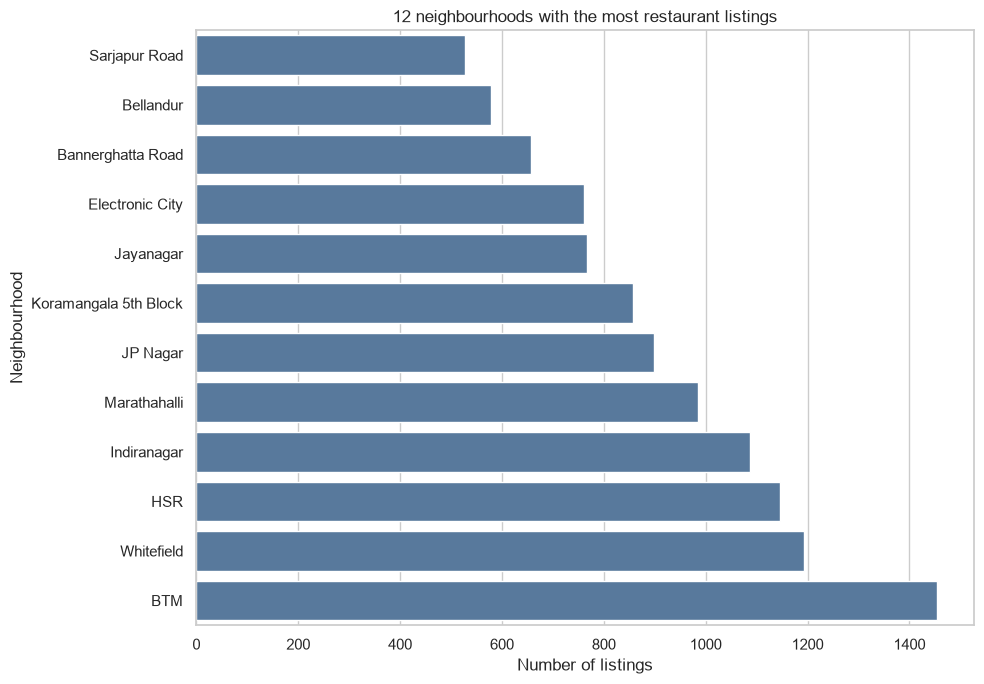

Saved: outputs\visualizations\01_top_neighbourhoods.png


In [6]:
location_counts = (df["location"].dropna().value_counts()
                   .head(12).sort_values())

display(location_counts.sort_values(ascending=False).to_frame("listing_count"))

plt.figure(figsize=(10, 7))
sns.barplot(x=location_counts.values, y=location_counts.index, color="#4C78A8")
plt.title("12 neighbourhoods with the most restaurant listings")
plt.xlabel("Number of listings")
plt.ylabel("Neighbourhood")
save_figure("01_top_neighbourhoods.png")

## 7. Rating distribution

The chart shows the distribution of available numeric ratings. Mean, median and skewness are reported as descriptive statistics; skewness is not inferred from the chart alone.

,rating
count,17161.000
mean,3.740
median,3.800
std,0.451
min,1.800
max,4.900


Rating skewness: -0.362


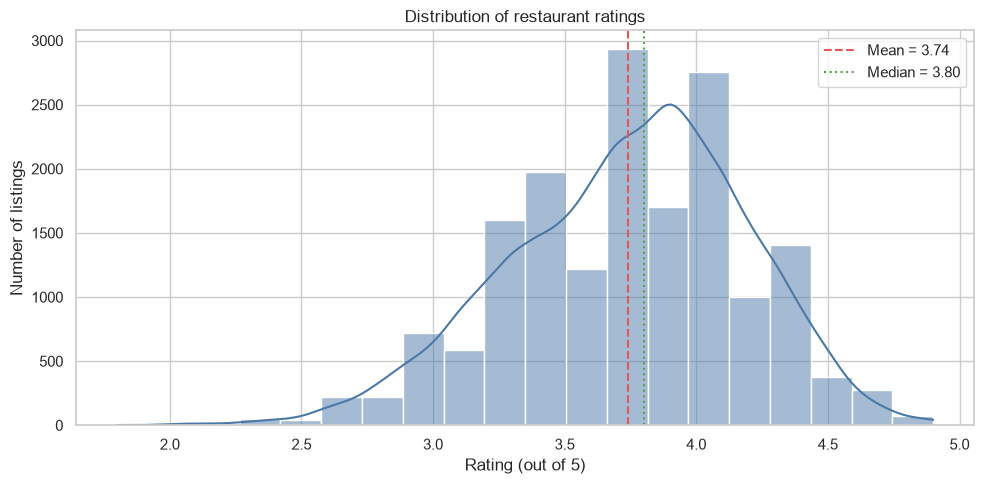

Saved: outputs\visualizations\02_rating_distribution.png


In [7]:
rating_stats = ratings_df["rating"].agg(["count", "mean", "median", "std", "min", "max"])
rating_skew = ratings_df["rating"].skew()
display(rating_stats.to_frame("rating").round(3))
print(f"Rating skewness: {rating_skew:.3f}")

plt.figure(figsize=(10, 5))
sns.histplot(ratings_df["rating"], bins=20, kde=True, color="#4C78A8")
plt.axvline(ratings_df["rating"].mean(), linestyle="--", color="#E45756",
            label=f"Mean = {ratings_df['rating'].mean():.2f}")
plt.axvline(ratings_df["rating"].median(), linestyle=":", color="#54A24B",
            label=f"Median = {ratings_df['rating'].median():.2f}")
plt.title("Distribution of restaurant ratings")
plt.xlabel("Rating (out of 5)")
plt.ylabel("Number of listings")
plt.legend()
save_figure("02_rating_distribution.png")

## 8. Restaurant types and cuisine tags

`rest_type` is a restaurant-format field (for example, casual dining or cafe). `cuisines` can contain multiple comma-separated cuisine tags, so it is split and exploded before counting. Cuisine counts represent tag occurrences, not necessarily unique restaurants.

,listing_count
rest_type,
Quick Bites,7383
Casual Dining,4375
Delivery,1282
Cafe,1157
"Takeaway, Delivery",1014
Dessert Parlor,891
"Casual Dining, Bar",444
Bakery,427
Beverage Shop,372


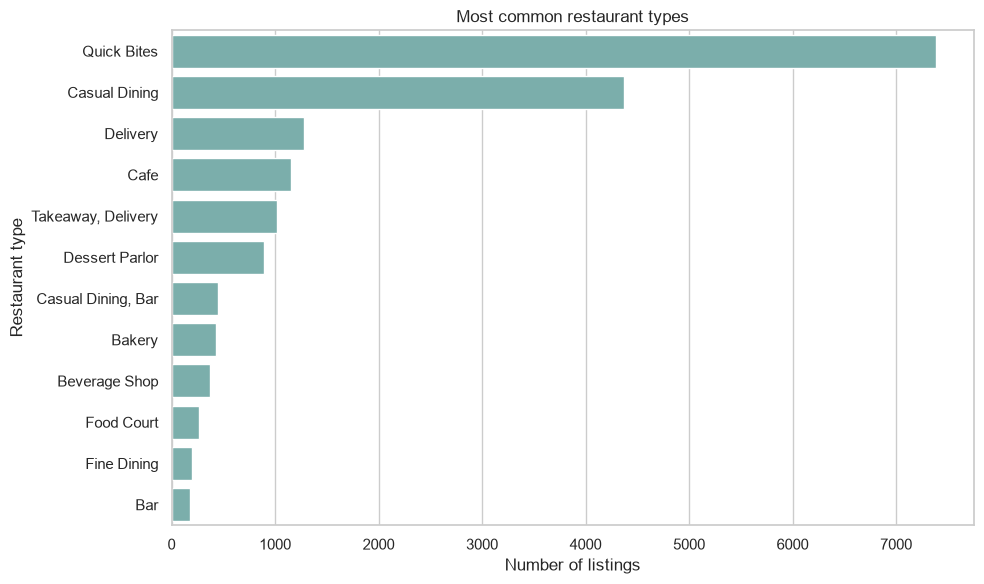

Saved: outputs\visualizations\03_top_restaurant_types.png


,tag_occurrences
cuisines,
North Indian,8468
Chinese,6079
South Indian,3485
Fast Food,3208
Biryani,2820
Continental,2232
Desserts,2122
Beverages,1983
Cafe,1683


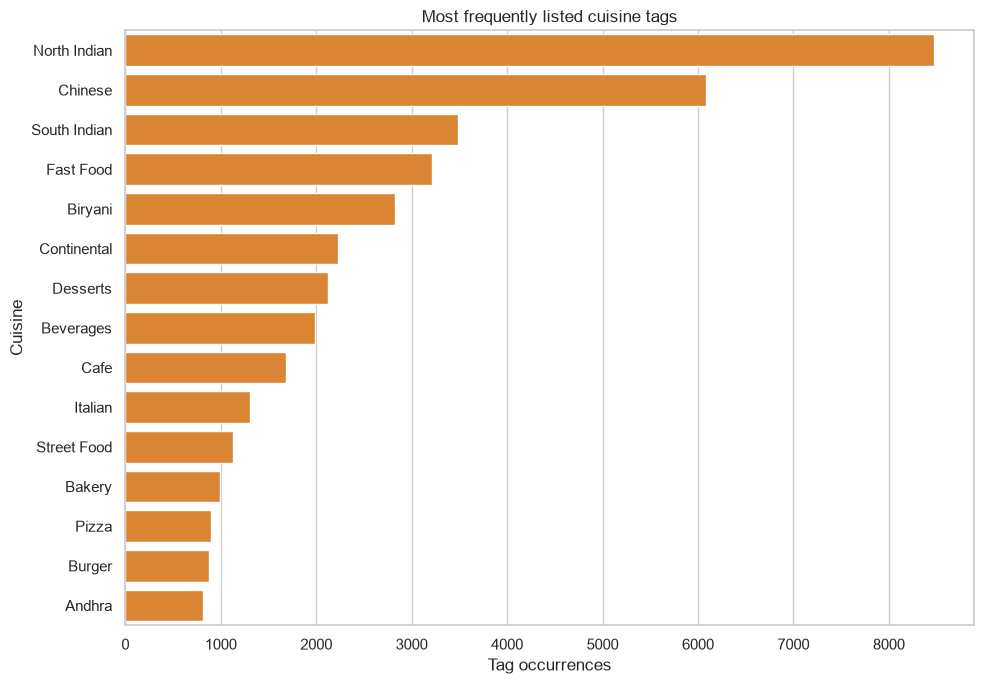

Saved: outputs\visualizations\04_top_cuisine_tags.png


In [8]:
rest_type_counts = df["rest_type"].dropna().value_counts().head(12)
display(rest_type_counts.to_frame("listing_count"))

plt.figure(figsize=(10, 6))
sns.barplot(x=rest_type_counts.values, y=rest_type_counts.index, color="#72B7B2")
plt.title("Most common restaurant types")
plt.xlabel("Number of listings")
plt.ylabel("Restaurant type")
save_figure("03_top_restaurant_types.png")

cuisine_tags = (df["cuisines"].dropna()
                .str.split(",")
                .explode()
                .astype("string")
                .str.strip())
cuisine_tags = cuisine_tags[cuisine_tags.ne("") & cuisine_tags.notna()]
cuisine_counts = cuisine_tags.value_counts().head(15)
display(cuisine_counts.to_frame("tag_occurrences"))

plt.figure(figsize=(10, 7))
sns.barplot(x=cuisine_counts.values, y=cuisine_counts.index, color="#F58518")
plt.title("Most frequently listed cuisine tags")
plt.xlabel("Tag occurrences")
plt.ylabel("Cuisine")
save_figure("04_top_cuisine_tags.png")

## 9. Online ordering and ratings

The comparison uses listings with a valid rating and a known Yes/No online-order flag. `Unknown` is excluded from the two-group visual comparison but is reported separately in the count table. This avoids silently treating unknown status as No.

,listing_count
online_order,
Yes,12359
No,8268


,count,mean,median,std
online_order,,,,
Yes,11341,3.75,3.8,0.43
No,5820,3.72,3.7,0.49


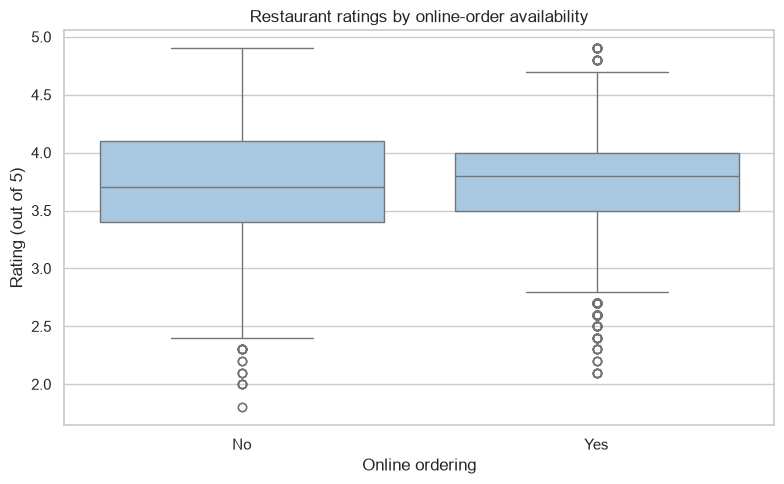

Saved: outputs\visualizations\05_ratings_by_online_order.png


In [9]:
online_counts = df["online_order"].value_counts().rename("listing_count").to_frame()
display(online_counts)

online_rating = ratings_df[ratings_df["online_order"].isin(["Yes", "No"])].copy()
display(show_group_summary(online_rating, "online_order", "rating"))

plt.figure(figsize=(8, 5))
sns.boxplot(data=online_rating, x="online_order", y="rating",
            order=["No", "Yes"], color="#9ECAE9")
plt.title("Restaurant ratings by online-order availability")
plt.xlabel("Online ordering")
plt.ylabel("Rating (out of 5)")
save_figure("05_ratings_by_online_order.png")

## 10. Table booking and ratings

As above, the plot compares known Yes/No groups only. Group sizes and summary statistics should be considered alongside the boxplot; differences are descriptive, not proof of an effect.

,listing_count
book_table,
No,17742
Yes,2885


,count,mean,median,std
book_table,,,,
Yes,2835,4.18,4.2,0.29
No,14326,3.65,3.7,0.43


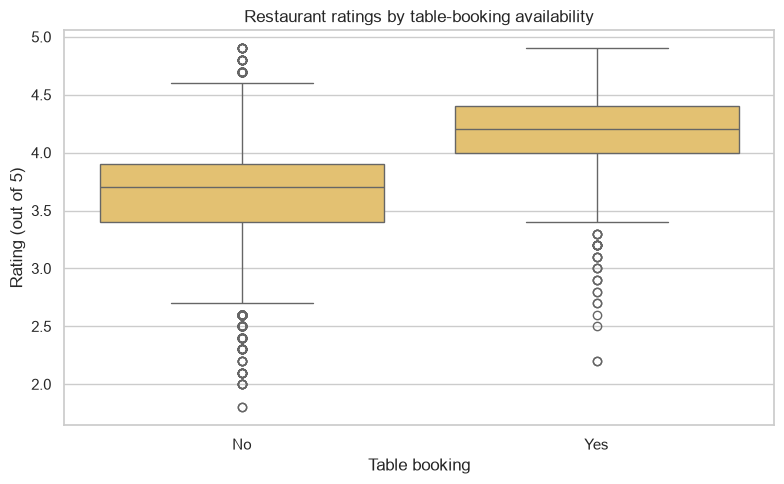

Saved: outputs\visualizations\06_ratings_by_table_booking.png


In [10]:
booking_counts = df["book_table"].value_counts().rename("listing_count").to_frame()
display(booking_counts)

booking_rating = ratings_df[ratings_df["book_table"].isin(["Yes", "No"])].copy()
display(show_group_summary(booking_rating, "book_table", "rating"))

plt.figure(figsize=(8, 5))
sns.boxplot(data=booking_rating, x="book_table", y="rating",
            order=["No", "Yes"], color="#F6C85F")
plt.title("Restaurant ratings by table-booking availability")
plt.xlabel("Table booking")
plt.ylabel("Rating (out of 5)")
save_figure("06_ratings_by_table_booking.png")

## 11. Approximate cost versus rating

A scatter plot can become difficult to read with many overlapping points. The visual uses a reproducible random sample (up to 3,000 listings), while correlation statistics are calculated on all rows with both values available.

Pearson correlation measures linear association and can be sensitive to outliers. Spearman correlation measures monotonic rank association. Neither establishes causation.

Listings with both rating and cost: 17,081


,method,correlation,n_listings
0,Pearson,0.407,17081
1,Spearman,0.425,17081


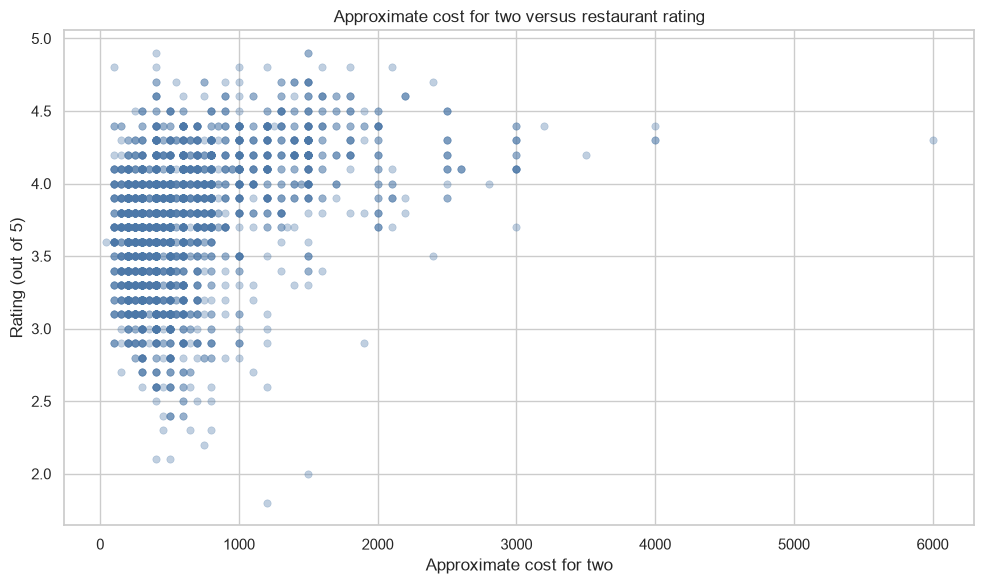

Saved: outputs\visualizations\07_cost_vs_rating_scatter.png


In [11]:
print(f"Listings with both rating and cost: {len(rating_cost_df):,}")
pearson_corr = rating_cost_df["cost_for_two"].corr(rating_cost_df["rating"], method="pearson")
spearman_corr = rating_cost_df["cost_for_two"].corr(rating_cost_df["rating"], method="spearman")
correlation_summary = pd.DataFrame({
    "method": ["Pearson", "Spearman"],
    "correlation": [pearson_corr, spearman_corr],
    "n_listings": [len(rating_cost_df), len(rating_cost_df)]
})
display(correlation_summary.round(3))

plot_sample = rating_cost_df.sample(
    n=min(3000, len(rating_cost_df)), random_state=42
) if len(rating_cost_df) else rating_cost_df

plt.figure(figsize=(10, 6))
sns.scatterplot(data=plot_sample, x="cost_for_two", y="rating",
                alpha=0.35, s=28, color="#4C78A8", edgecolor=None)
plt.title("Approximate cost for two versus restaurant rating")
plt.xlabel("Approximate cost for two")
plt.ylabel("Rating (out of 5)")
save_figure("07_cost_vs_rating_scatter.png")

## 12. Ratings and costs across price bands

Price bands are analytical groupings chosen for this project, not official market categories. Missing costs are not assigned to a band.

,listings,mean_rating,median_rating,median_cost
price_band,,,,
Up to ₹400,10536,3.61,3.6,300.0
₹401–₹800,6669,3.72,3.8,600.0
"₹801–₹1,200",1627,4.0,4.1,1000.0
"Above ₹1,200",1669,4.22,4.2,1500.0


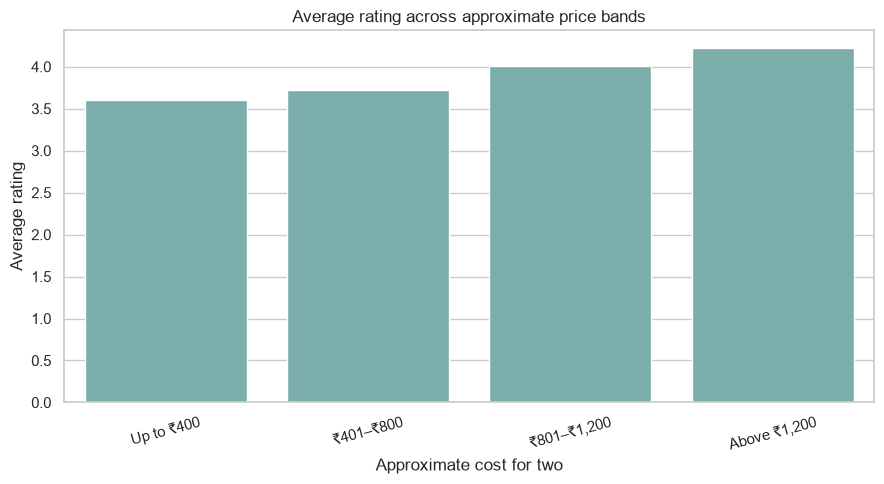

Saved: outputs\visualizations\08_average_rating_by_price_band.png


In [12]:
price_bins = [0, 400, 800, 1200, np.inf]
price_labels = ["Up to ₹400", "₹401–₹800", "₹801–₹1,200", "Above ₹1,200"]
df["price_band"] = pd.cut(
    df["cost_for_two"], bins=price_bins, labels=price_labels,
    include_lowest=True, right=True
)

price_summary = (df.dropna(subset=["price_band"])
                 .groupby("price_band", observed=False)
                 .agg(listings=("name", "size"),
                      mean_rating=("rating", "mean"),
                      median_rating=("rating", "median"),
                      median_cost=("cost_for_two", "median"))
                 .round(2))
display(price_summary)

plt.figure(figsize=(9, 5))
sns.barplot(data=df.dropna(subset=["price_band", "rating"]),
            x="price_band", y="rating", errorbar=None,
            color="#72B7B2", order=price_labels)
plt.title("Average rating across approximate price bands")
plt.xlabel("Approximate cost for two")
plt.ylabel("Average rating")
plt.xticks(rotation=15)
save_figure("08_average_rating_by_price_band.png")

## 13. Table booking and approximate cost

This comparison explores whether listings that offer table booking also tend to have different approximate costs. The plot is descriptive and does not imply that booking availability causes higher prices.

,count,mean,median,std
book_table,,,,
Yes,2885,1305.63,1200.0,619.16
No,17616,450.53,400.0,291.83


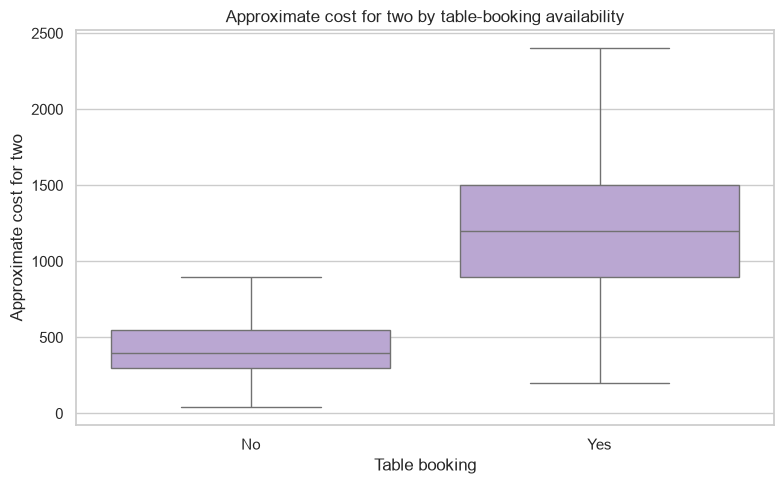

Saved: outputs\visualizations\09_cost_by_table_booking.png


In [13]:
booking_cost = cost_df[cost_df["book_table"].isin(["Yes", "No"])].copy()
display(show_group_summary(booking_cost, "book_table", "cost_for_two"))

plt.figure(figsize=(8, 5))
sns.boxplot(data=booking_cost, x="book_table", y="cost_for_two",
            order=["No", "Yes"], showfliers=False, color="#B9A0D9")
plt.title("Approximate cost for two by table-booking availability")
plt.xlabel("Table booking")
plt.ylabel("Approximate cost for two")
save_figure("09_cost_by_table_booking.png")

## 14. Restaurant types with higher average ratings

To avoid ranking categories with only a handful of observations, this table includes restaurant types with at least 30 listings that have a valid rating. Change the threshold only if you explain why.

,listings,mean_rating,median_rating
rest_type,,,
"Pub, Microbrewery",32,4.51,4.5
"Microbrewery, Casual Dining",67,4.37,4.4
"Casual Dining, Cafe",117,4.25,4.3
"Dessert Parlor, Cafe",60,4.22,4.3
"Bar, Casual Dining",156,4.22,4.3
"Casual Dining, Pub",59,4.2,4.2
Fine Dining,200,4.18,4.2
"Cafe, Casual Dining",70,4.18,4.2
"Cafe, Dessert Parlor",47,4.16,4.2


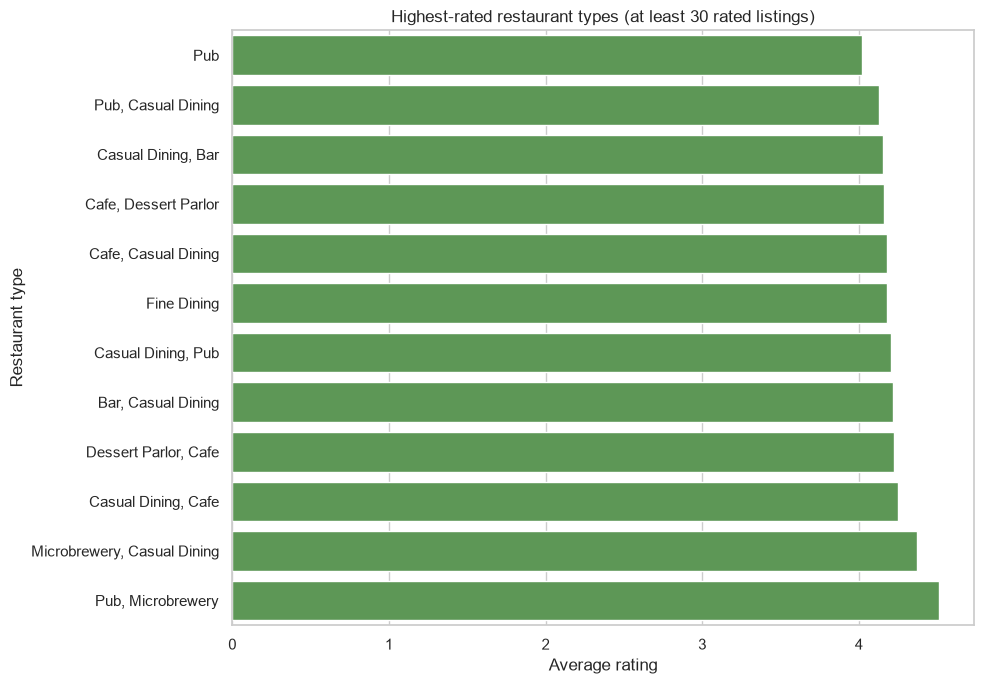

Saved: outputs\visualizations\10_top_rated_restaurant_types.png


In [14]:
MIN_REST_TYPE_N = 30
rest_rating = (ratings_df.dropna(subset=["rest_type"])
               .groupby("rest_type")
               .agg(listings=("rating", "size"),
                    mean_rating=("rating", "mean"),
                    median_rating=("rating", "median"))
               .query("listings >= @MIN_REST_TYPE_N")
               .sort_values(["mean_rating", "listings"], ascending=[False, False]))
display(rest_rating.head(15).round(2))

top_rest_rating = rest_rating.head(12).sort_values("mean_rating")
plt.figure(figsize=(10, 7))
sns.barplot(data=top_rest_rating.reset_index(), x="mean_rating", y="rest_type",
            color="#54A24B")
plt.title(f"Highest-rated restaurant types (at least {MIN_REST_TYPE_N} rated listings)")
plt.xlabel("Average rating")
plt.ylabel("Restaurant type")
save_figure("10_top_rated_restaurant_types.png")

## 15. Neighbourhoods with higher average ratings

Only neighbourhoods with at least 50 listings with a valid rating are included. This minimum-count rule reduces the chance of overemphasising tiny groups, although it does not remove all sampling bias.

,listings,mean_rating,median_rating
location,,,
Lavelle Road,191,4.2,4.3
Koramangala 5th Block,826,4.12,4.2
St. Marks Road,121,4.11,4.2
Koramangala 3rd Block,54,4.06,4.1
Church Street,229,4.05,4.1
Koramangala 4th Block,273,4.02,4.1
Residency Road,216,4.0,4.1
MG Road,269,3.99,4.1
Richmond Road,159,3.97,4.1


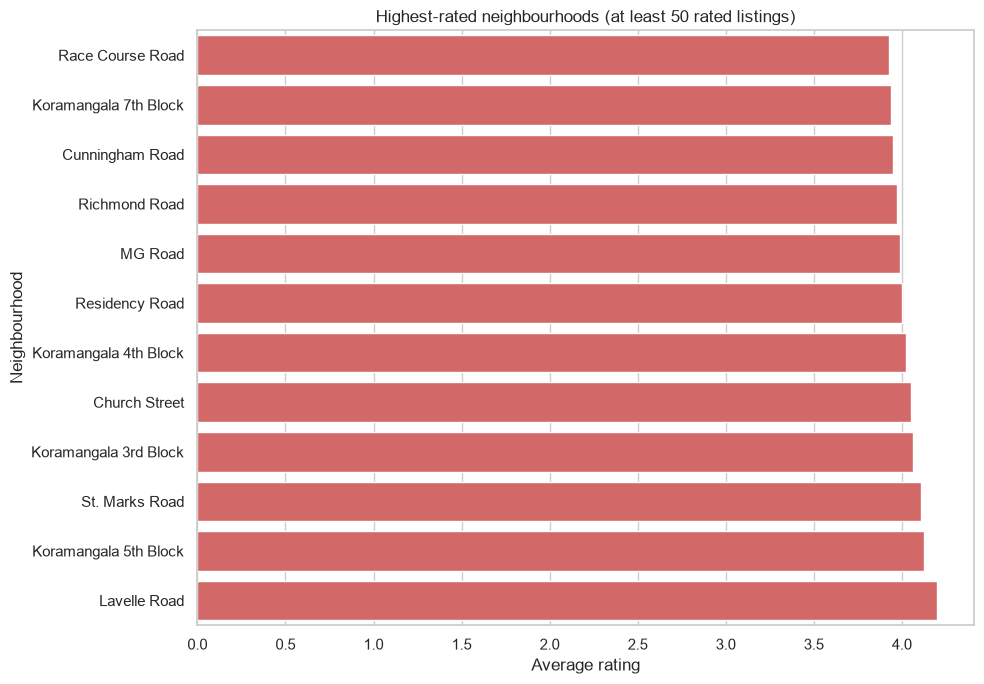

Saved: outputs\visualizations\11_top_rated_neighbourhoods.png


In [15]:
MIN_LOCATION_N = 50
location_rating = (ratings_df.dropna(subset=["location"])
                   .groupby("location")
                   .agg(listings=("rating", "size"),
                        mean_rating=("rating", "mean"),
                        median_rating=("rating", "median"))
                   .query("listings >= @MIN_LOCATION_N")
                   .sort_values(["mean_rating", "listings"], ascending=[False, False]))
display(location_rating.head(15).round(2))

top_location_rating = location_rating.head(12).sort_values("mean_rating")
plt.figure(figsize=(10, 7))
sns.barplot(data=top_location_rating.reset_index(), x="mean_rating", y="location",
            color="#E45756")
plt.title(f"Highest-rated neighbourhoods (at least {MIN_LOCATION_N} rated listings)")
plt.xlabel("Average rating")
plt.ylabel("Neighbourhood")
save_figure("11_top_rated_neighbourhoods.png")

## 16. Votes and rating bands

Votes are a measure of recorded engagement in this dataset, not a direct measure of quality. A high vote count may reflect visibility, age, popularity or other factors not captured here.

In [16]:
rating_bins = [0, 2.5, 3.0, 3.5, 4.0, 4.5, 5.0]
rating_labels = ["0–2.5", "2.5–3.0", "3.0–3.5", "3.5–4.0", "4.0–4.5", "4.5–5.0"]
df["rating_band"] = pd.cut(
    df["rating"], bins=rating_bins, labels=rating_labels,
    include_lowest=True, right=True
)

votes_by_band = (df.dropna(subset=["rating_band", "votes"])
                 .groupby("rating_band", observed=False)
                 .agg(listings=("votes", "size"),
                      total_votes=("votes", "sum"),
                      median_votes=("votes", "median"),
                      mean_votes=("votes", "mean"))
                 .round(2))
display(votes_by_band)

,listings,total_votes,median_votes,mean_votes
rating_band,,,,
0–2.5,110,20491,149.5,186.28
2.5–3.0,1157,118560,50.0,102.47
3.0–3.5,4161,198279,12.0,47.65
3.5–4.0,7319,1596117,90.0,218.08
4.0–4.5,4072,4142201,557.0,1017.24
4.5–5.0,342,1143945,2294.0,3344.87


## 17. Online-order availability across neighbourhoods

The percentage is calculated only among listings with a known Yes/No online-order flag. Unknown records are excluded from the denominator and their counts are shown separately. Neighbourhoods need at least 30 known-status listings to appear.

,known_service_listings,online_order_yes,online_order_share_pct,unknown_status_listings
location,,,,
"Varthur Main Road, Whitefield",89,78,87.64,0
Nagawara,110,93,84.55,0
Kumaraswamy Layout,109,92,84.40,0
Sahakara Nagar,45,36,80.00,0
"ITPL Main Road, Whitefield",65,51,78.46,0
Jeevan Bhima Nagar,143,112,78.32,0
Yeshwantpur,76,58,76.32,0
Kaggadasapura,67,51,76.12,0
RT Nagar,56,42,75.00,0


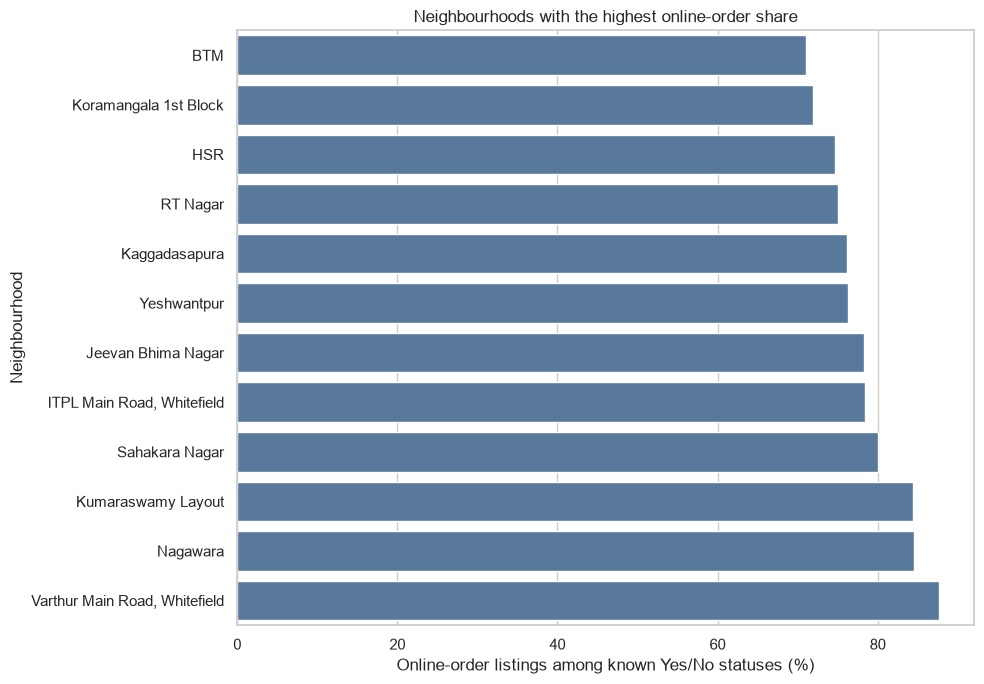

Saved: outputs\visualizations\12_online_order_share_by_neighbourhood.png


In [17]:
known_online = df[df["online_order"].isin(["Yes", "No"])].copy()
online_by_location = (known_online.dropna(subset=["location"])
                      .groupby("location")
                      .agg(known_service_listings=("online_order", "size"),
                           online_order_yes=("online_order", lambda s: (s == "Yes").sum()))
                      )
online_by_location["online_order_share_pct"] = (
    online_by_location["online_order_yes"] /
    online_by_location["known_service_listings"] * 100
)
unknown_by_location = (df[df["online_order"].eq("Unknown")]
                       .dropna(subset=["location"])
                       .groupby("location").size()
                       .rename("unknown_status_listings"))
online_by_location = online_by_location.join(unknown_by_location, how="left")
online_by_location["unknown_status_listings"] = (
    online_by_location["unknown_status_listings"].fillna(0).astype(int)
)
online_by_location = (online_by_location
                      .query("known_service_listings >= 30")
                      .sort_values("online_order_share_pct", ascending=False))
display(online_by_location.head(15).round(2))

plot_online = online_by_location.head(12).sort_values("online_order_share_pct")
plt.figure(figsize=(10, 7))
sns.barplot(data=plot_online.reset_index(), x="online_order_share_pct",
            y="location", color="#4C78A8")
plt.title("Neighbourhoods with the highest online-order share")
plt.xlabel("Online-order listings among known Yes/No statuses (%)")
plt.ylabel("Neighbourhood")
save_figure("12_online_order_share_by_neighbourhood.png")

## 18. Automatically generated findings to review

This section prints actual values from the dataset after the notebook has been run. Review the numbers and context before using any findings in a public portfolio description.

In [18]:
print("DATASET SUMMARY")
print(f"Analytical listings: {len(df):,}")
print(f"Listings with ratings: {df['rating'].notna().sum():,}")
print(f"Listings with approximate cost: {df['cost_for_two'].notna().sum():,}")
print(f"Listings with both rating and cost: {len(rating_cost_df):,}")

if not location_counts.empty:
    print(f"Most represented neighbourhood: {location_counts.idxmax()} "
          f"({location_counts.max():,} listings)")

if not ratings_df.empty:
    print(f"Mean rating: {ratings_df['rating'].mean():.2f}/5")
    print(f"Median rating: {ratings_df['rating'].median():.2f}/5")
    print(f"Rating skewness: {ratings_df['rating'].skew():.3f}")

if pd.notna(pearson_corr):
    print(f"Pearson cost-rating correlation: {pearson_corr:.3f}")
if pd.notna(spearman_corr):
    print(f"Spearman cost-rating correlation: {spearman_corr:.3f}")

print("\nInterpret these as descriptive patterns, not causal effects.")

DATASET SUMMARY
Analytical listings: 20,627
Listings with ratings: 17,161
Listings with approximate cost: 20,501
Listings with both rating and cost: 17,081
Most represented neighbourhood: BTM (1,454 listings)
Mean rating: 3.74/5
Median rating: 3.80/5
Rating skewness: -0.362
Pearson cost-rating correlation: 0.407
Spearman cost-rating correlation: 0.425

Interpret these as descriptive patterns, not causal effects.


## 19. Interpretation checklist

Before writing conclusions, answer these questions using the outputs above:

- Are the most represented neighbourhoods also among the highest-rated neighbourhoods, or are these different patterns?
- Is the rating distribution concentrated around a particular range? What do the mean, median and skewness indicate?
- Are online-order and table-booking groups different in median rating as well as mean rating? How large are the groups?
- Is the cost-rating relationship weak, moderate or strong? Do Pearson and Spearman tell a similar story?
- Do price bands show a consistent rating pattern, or are differences small/overlapping?
- Which restaurant-type and neighbourhood rankings remain meaningful after minimum sample-size thresholds?
- How much missingness exists in ratings, cost and service flags, and how might it affect the results?

Avoid words such as **causes**, **impact**, **proves** or **significantly** unless a suitable statistical design and test support them. A visible difference in a chart is not automatically statistically significant or practically important.

## 20. Limitations and possible extensions

### Limitations
- The dataset is a historical snapshot; it should not be treated as a live view of Bengaluru restaurants.
- There is no dependable time field for analysing changes over time.
- Missing ratings and costs may not be random. Analyses using available values can therefore reflect selection effects.
- Approximate cost for two is not an exact bill and may not be comparable across all restaurant formats.
- A restaurant listing may be duplicated, outdated or otherwise imperfectly represented.
- Correlation and group comparisons do not establish causation.
- Cuisine tags are multi-label; cuisine occurrence totals can exceed the number of listings.

### Possible extensions
- Add confidence intervals for group means and robust statistical comparisons where assumptions are checked.
- Explore log-transformed cost and robust correlation measures.
- Build a simple predictive baseline only after defining a clear target and avoiding data leakage.
- Compare results across alternative minimum sample thresholds.
- Add a data-source citation and dataset-specific licence notes once the original source is confirmed.

## 21. Export and reproducibility notes

All figures are saved to `outputs/visualizations/`. The raw CSV is intentionally excluded from version control. If you share this repository, include the data source, access instructions and applicable licence information without redistributing data unless permission is clear.

In [19]:
print("Visualisation files:")
for path in sorted(OUTPUT_DIR.glob("*.png")):
    print("-", path.name)

print("\nNotebook run complete.")

Visualisation files:
- 01_top_neighbourhoods.png
- 02_rating_distribution.png
- 03_top_restaurant_types.png
- 04_top_cuisine_tags.png
- 05_ratings_by_online_order.png
- 06_ratings_by_table_booking.png
- 07_cost_vs_rating_scatter.png
- 08_average_rating_by_price_band.png
- 09_cost_by_table_booking.png
- 10_top_rated_restaurant_types.png
- 11_top_rated_neighbourhoods.png
- 12_online_order_share_by_neighbourhood.png

Notebook run complete.
